In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [3]:
df = pd.read_csv('../Datasets/gurgaon_properties_missing_value_imputation.csv')

In [4]:
df.shape

(3554, 18)

In [5]:
df.head()

,property_type,society,sector,price,price_per_sqft,bedRoom,bathroom,balcony,floorNum,agePossession,built_up_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_score
0,flat,signature global park 4,sector 36,0.82,7586.0,3,2,2,2.0,New Property,850.0,0,0,0,0,0,1,8
1,flat,smart world gems,sector 89,0.95,8597.0,2,2,2,4.0,New Property,1226.0,1,1,0,0,0,1,38
2,flat,breez global hill view,sohna road,0.32,5470.0,2,2,1,17.0,New Property,1000.0,0,0,0,0,0,1,49
3,flat,bestech park view sanskruti,sector 92,1.60,8020.0,3,4,3+,10.0,Relatively New,1615.0,0,1,0,0,1,2,174
4,flat,suncity avenue,sector 102,0.48,9023.0,2,2,1,5.0,Relatively New,582.0,0,0,1,0,0,1,159


In [7]:
latlong = pd.read_csv('../Datasets/latlong.csv')

In [8]:
latlong

,sector,coordinates
0,sector 1,"28.3663° N, 76.9456° E"
1,sector 2,"28.5095° N, 77.0320° E"
2,sector 3,"28.4909° N, 77.0176° E"
3,sector 4,"28.4738° N, 77.0107° E"
4,sector 5,"28.4794° N, 77.0176° E"
...,...,...
124,sector 113,"28.5287° N, 77.0233° E"
125,sector 114,"28.5334° N, 77.0118° E"
126,sector 115,"28.5385° N, 77.0061° E"
127,gwal pahari,"28.4484° N, 77.0210° E"


In [9]:
latlong['latitude'] = latlong['coordinates'].str.split(',').str.get(0).str.split('°').str.get(0).astype('float')

In [10]:
latlong['longitude'] = latlong['coordinates'].str.split(',').str.get(1).str.split('°').str.get(0).astype('float')

In [11]:
latlong.head()

,sector,coordinates,latitude,longitude
0,sector 1,"28.3663° N, 76.9456° E",28.3663,76.9456
1,sector 2,"28.5095° N, 77.0320° E",28.5095,77.0320
2,sector 3,"28.4909° N, 77.0176° E",28.4909,77.0176
3,sector 4,"28.4738° N, 77.0107° E",28.4738,77.0107
4,sector 5,"28.4794° N, 77.0176° E",28.4794,77.0176


In [12]:
new_df = df.merge(latlong, on='sector')

In [13]:
new_df.columns

Index(['property_type', 'society', 'sector', 'price', 'price_per_sqft',
       'bedRoom', 'bathroom', 'balcony', 'floorNum', 'agePossession',
       'built_up_area', 'study room', 'servant room', 'store room',
       'pooja room', 'others', 'furnishing_type', 'luxury_score',
       'coordinates', 'latitude', 'longitude'],
      dtype='object')

In [15]:
group_df = new_df.groupby('sector')[
    ['price', 'price_per_sqft', 'built_up_area', 'latitude', 'longitude']
].mean()

In [16]:
group_df

,price,price_per_sqft,built_up_area,latitude,longitude
sector,,,,,
gwal pahari,3.192222,9585.777778,3056.166667,28.4484,77.0210
manesar,0.962258,4608.064516,2027.367742,28.3515,76.9428
sector 1,1.860000,8249.833333,2327.833333,28.3663,76.9456
sector 102,1.696636,10603.822430,1556.130841,28.4750,76.9715
sector 103,1.495000,7445.785714,1865.428571,28.4949,76.9845
...,...,...,...,...,...
sector 92,0.934000,5928.290000,1571.341800,28.4079,76.9153
sector 93,0.848889,8009.888889,1017.000000,28.4153,76.9326
sector 95,0.480545,5602.509091,995.981818,28.4172,76.9081


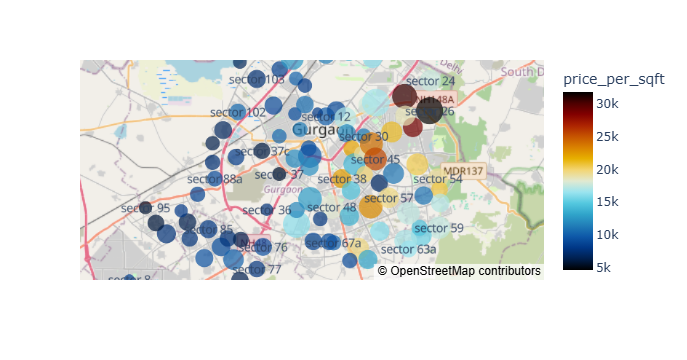

In [20]:
fig = px.scatter_map(
    group_df,
    lat="latitude",
    lon="longitude",
    color="price_per_sqft",
    size="built_up_area",
    color_continuous_scale=px.colors.cyclical.IceFire,
    zoom=10,
    map_style="open-street-map",
    text=group_df.index
)

fig.show()

In [21]:
new_df.to_csv('data_viz1.csv',index=False)

In [22]:
df1 = pd.read_csv('../Datasets/gurgaon_properties.csv')

In [23]:
df1.head()

,property_name,property_type,society,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,additionalRoom,address,floorNum,facing,agePossession,nearbyLocations,description,furnishDetails,features,rating
0,3 BHK Flat in Sector 102 Gurgaon,flat,conscient heritage max,1.70,11333.0,1500.0,Super Built up area 1942(180.42 sq.m.)Built Up...,3,4,3+,"servant room,pooja room","100, Sector 102 Gurgaon, Gurgaon, Haryana",8.0,North-East,1 to 5 Year Old,"['Huda Metro Station', 'Ocus Medley Mall', 'Th...",Conscient heritage max is one of gurgaon's mos...,"['5 Fan', '1 Exhaust Fan', '1 Stove', '4 Light...","['Centrally Air Conditioned', 'Water purifier'...","['Green Area5 out of 5', 'Construction5 out of..."
1,2 BHK Flat in Sohna,flat,gls arawali homes,0.27,4600.0,587.0,Super Built up area 576(53.51 sq.m.),2,2,2,not available,"Sohna, Gurgaon, Haryana",5.0,NaN,0 to 1 Year Old,"['Huda City Centre', 'Golf Course Road', 'Delh...",Tower 13 floor 5th house no. 508. Freehold pro...,[],"['Feng Shui / Vaastu Compliant', 'Intercom Fac...","['Management4 out of 5', 'Green Area5 out of 5..."
2,3 Bedroom House for sale in Rajendra Park,house,independent,0.60,13333.0,450.0,Built Up area: 450 (41.81 sq.m.),3,3,0,not available,"Rajendra Park, Sector 105, Rajendra Park, Gurg...",3.0,NaN,undefined,"['Palam Vihar Vyapar kendra', 'Chintapurni Man...",Best in class property available at rajendra p...,NaN,NaN,"['Environment4 out of 5', 'Lifestyle4 out of 5..."
3,3 BHK Flat in Sector 65 Gurgaon,flat,m3m skycity,2.85,15590.0,1828.0,Super Built up area 1828(169.83 sq.m.),3,3,3,not available,"Sector 65 Gurgaon, Gurgaon, Haryana",43.0,South,Dec 2024,"['Sector 55 Metro Station', 'Eros City Square'...",M3m skycity is one of the most popular destina...,"['1 Exhaust Fan', '1 AC', '1 Chimney', '1 Modu...","['Security / Fire Alarm', 'Feng Shui / Vaastu ...","['Environment4 out of 5', 'Safety4 out of 5', ..."
4,2 BHK Flat in Sector 85 Gurgaon,flat,ss the leaf,1.20,10452.0,1148.0,Super Built up area 1640(152.36 sq.m.)Carpet a...,2,2,3+,store room,"Tower-1, Sector 85 Gurgaon, Gurgaon, Haryana",2.0,West,1 to 5 Year Old,"['Sapphire 83 Mall', 'Dwarka Expressway', 'Cen...",This beautiful 2 bhk flat in sector 85 gurgaon...,"['10 Light', '4 AC', 'No Bed', 'No Chimney', '...","['Centrally Air Conditioned', 'Water purifier'...","['Green Area4.5 out of 5', 'Construction4.5 ou..."


In [24]:
wordcloud_df = df1.merge(df, left_index=True, right_index=True)[['features','sector']]

In [25]:
wordcloud_df.head()

,features,sector
0,"['Centrally Air Conditioned', 'Water purifier'...",sector 36
1,"['Feng Shui / Vaastu Compliant', 'Intercom Fac...",sector 89
2,NaN,sohna road
3,"['Security / Fire Alarm', 'Feng Shui / Vaastu ...",sector 92
4,"['Centrally Air Conditioned', 'Water purifier'...",sector 102


In [26]:
import ast
main = []
for item in wordcloud_df['features'].dropna().apply(ast.literal_eval):
    main.extend(item)

In [27]:
main

['Centrally Air Conditioned',
 'Water purifier',
 'Security / Fire Alarm',
 'Feng Shui / Vaastu Compliant',
 'Private Garden / Terrace',
 'Intercom Facility',
 'Lift(s)',
 'High Ceiling Height',
 'Maintenance Staff',
 'False Ceiling Lighting',
 'Water Storage',
 'Separate entry for servant room',
 'No open drainage around',
 'Bank Attached Property',
 'Piped-gas',
 'Internet/wi-fi connectivity',
 'Recently Renovated',
 'Visitor Parking',
 'Swimming Pool',
 'Park',
 'Security Personnel',
 'Natural Light',
 'Airy Rooms',
 'Spacious Interiors',
 'Low Density Society',
 'Waste Disposal',
 'Rain Water Harvesting',
 'Water softening plant',
 'Shopping Centre',
 'Fitness Centre / GYM',
 'Club house / Community Center',
 'Feng Shui / Vaastu Compliant',
 'Intercom Facility',
 'Lift(s)',
 'Park',
 'Shopping Centre',
 'Fitness Centre / GYM',
 'Club house / Community Center',
 'Rain Water Harvesting',
 'Security / Fire Alarm',
 'Feng Shui / Vaastu Compliant',
 'Intercom Facility',
 'Lift(s)',
 'Ce

In [28]:
from wordcloud import WordCloud

In [29]:
feature_text = ' '.join(main)

In [30]:
import pickle
pickle.dump(feature_text, open('feature_text.pkl','wb'))

In [31]:
feature_text

'Centrally Air Conditioned Water purifier Security / Fire Alarm Feng Shui / Vaastu Compliant Private Garden / Terrace Intercom Facility Lift(s) High Ceiling Height Maintenance Staff False Ceiling Lighting Water Storage Separate entry for servant room No open drainage around Bank Attached Property Piped-gas Internet/wi-fi connectivity Recently Renovated Visitor Parking Swimming Pool Park Security Personnel Natural Light Airy Rooms Spacious Interiors Low Density Society Waste Disposal Rain Water Harvesting Water softening plant Shopping Centre Fitness Centre / GYM Club house / Community Center Feng Shui / Vaastu Compliant Intercom Facility Lift(s) Park Shopping Centre Fitness Centre / GYM Club house / Community Center Rain Water Harvesting Security / Fire Alarm Feng Shui / Vaastu Compliant Intercom Facility Lift(s) Centrally Air Conditioned Maintenance Staff Water Storage No open drainage around Visitor Parking Swimming Pool Park Security Personnel Natural Light Airy Rooms Spacious Inter

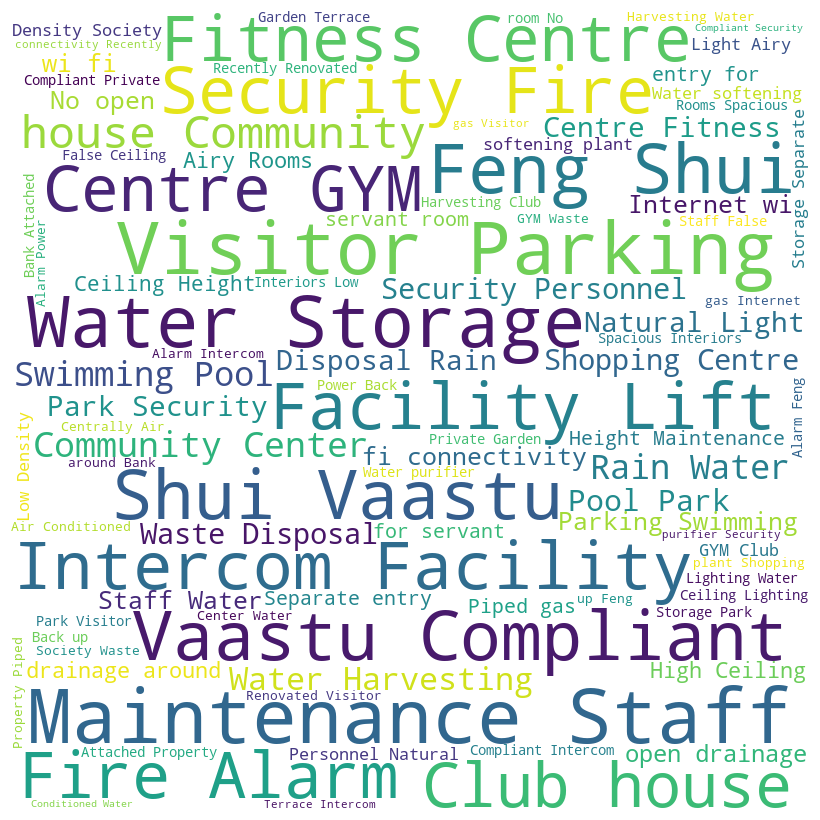

In [32]:
plt.rcParams["font.family"] = "Arial"

wordcloud = WordCloud(width = 800, height = 800, 
                      background_color ='white', 
                      stopwords = set(['s']),  # Any stopwords you'd like to exclude
                      min_font_size = 10).generate(feature_text)

plt.figure(figsize = (8, 8), facecolor = None) 
plt.imshow(wordcloud, interpolation='bilinear') 
plt.axis("off") 
plt.tight_layout(pad = 0) 
plt.show() # st.pyplot()

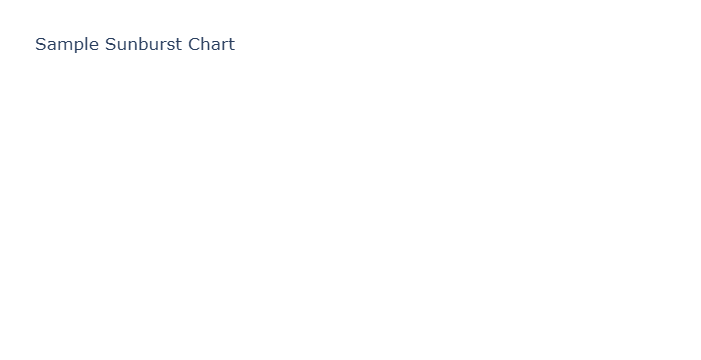

In [33]:
data = dict(
    names=["A", "B", "C", "D", "E", "F"],
    parents=["", "", "", "A", "A", "C"],
    values=[10, 20, 30, 40, 50, 60],
)

fig = px.sunburst(
    df1,
    names='property_type',
    values='price_per_sqft',
    parents='bedRoom',
    title="Sample Sunburst Chart"
)
fig.show()

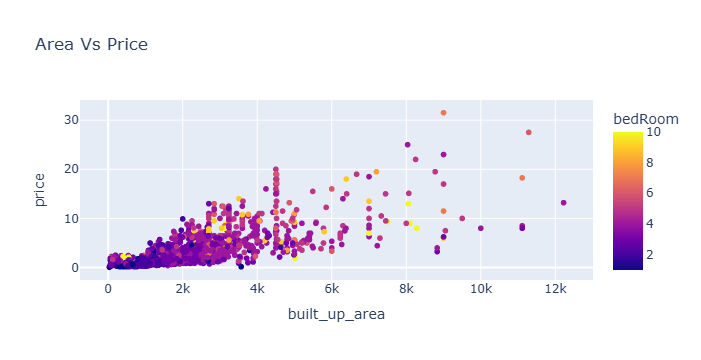

In [34]:
fig = px.scatter(df, x="built_up_area", y="price", color="bedRoom", title="Area Vs Price")

# Show the plot
fig.show()

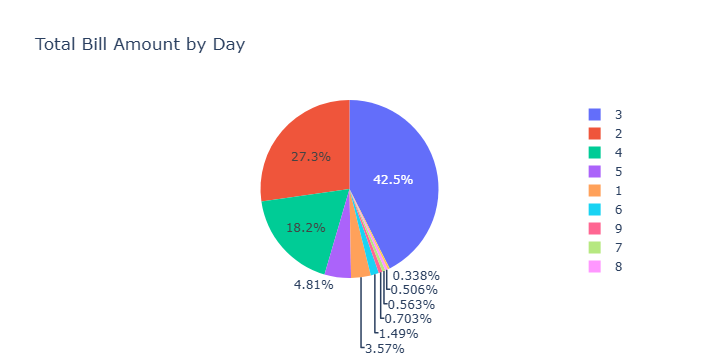

In [35]:
fig = px.pie(df, names='bedRoom', title='Total Bill Amount by Day')

# Show the plot
fig.show()

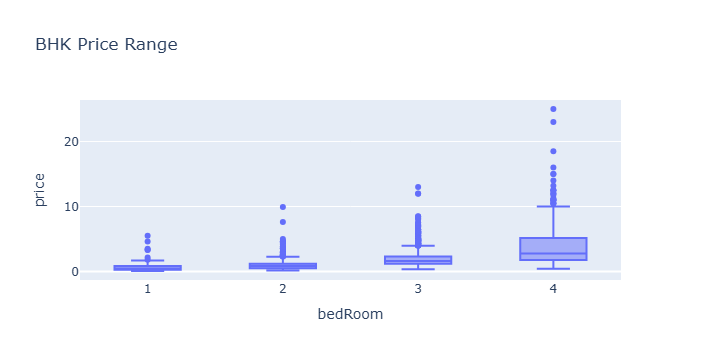

In [36]:
temp_df = df[df['bedRoom'] <= 4]
# Create side-by-side boxplots of the total bill amounts by day
fig = px.box(temp_df, x='bedRoom', y='price', title='BHK Price Range')

# Show the plot
fig.show()


C:\Users\aloko\AppData\Local\Temp\ipykernel_20120\3761596323.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df[df['property_type'] == 'house']['price'])
C:\Users\aloko\AppData\Local\Temp\ipykernel_20120\3761596323.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df[df['property_type'] ==

<Axes: xlabel='price', ylabel='Density'>

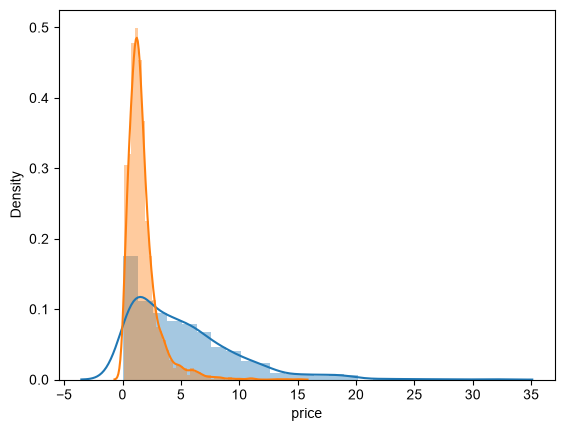

In [37]:
sns.distplot(df[df['property_type'] == 'house']['price'])
sns.distplot(df[df['property_type'] == 'flat']['price'])

In [38]:
new_df['sector'].unique().tolist().insert(0,'overall')